In [ ]:
import os, sys, math, re, time, pickle, itertools, hashlib
import dataclasses
from pathlib import Path

from google.colab import drive
drive.mount('/content/drive')

!git clone https://github.com/JoeyTurn/kernels_can_icl.git
!git clone https://github.com/dkarkada/expt-core.git

sys.path.insert(0, "/content/kernels_can_icl")
sys.path.insert(0, "/content/expt-core")

DATASETPATH = "/content/drive/MyDrive/datasets"
RESULTPATH  = "/content/drive/MyDrive/results"
os.environ["DATASETPATH"] = DATASETPATH
os.environ["RESULTPATH"]  = RESULTPATH
os.makedirs(DATASETPATH, exist_ok=True)
os.makedirs(RESULTPATH,  exist_ok=True)

Mounted at /content/drive
Cloning into 'kernel_ICL'...
remote: Enumerating objects: 784, done.
remote: Counting objects: 100% (319/319), done.
remote: Compressing objects: 100% (221/221), done.
remote: Total 784 (delta 194), reused 217 (delta 93), pack-reused 465 (from 1)
Receiving objects: 100% (784/784), 55.31 MiB | 18.75 MiB/s, done.
Resolving deltas: 100% (388/388), done.
Cloning into 'expt-core'...
remote: Enumerating objects: 58, done.
remote: Counting objects: 100% (58/58), done.
remote: Compressing objects: 100% (41/41), done.
remote: Total 58 (delta 28), reused 47 (delta 17), pack-reused 0 (from 0)
Receiving objects: 100% (58/58), 16.11 KiB | 8.05 MiB/s, done.
Resolving deltas: 100% (28/28), done.


In [ ]:
sys.path.insert(0, "/content/kernels_can_icl")
sys.path.insert(0, "/content/expt-core")

DATASETPATH = "/content/drive/MyDrive/datasets"
RESULTPATH  = "/content/drive/MyDrive/results"
os.environ["DATASETPATH"] = DATASETPATH
os.environ["RESULTPATH"]  = RESULTPATH
os.makedirs(DATASETPATH, exist_ok=True)
os.makedirs(RESULTPATH,  exist_ok=True)

In [ ]:
import numpy as np
import torch
import matplotlib.pyplot as plt
from scipy.optimize import brentq
from scipy.special import comb

from kernels_can_icl.monomial import Monomial
from kernels_can_icl.level_coefficients import get_polynomial_coefficients
from kernels_can_icl.task_distrs import RegressionTaskDistribution
from kernels_can_icl.eigenlearning import compute_learnabilities
from kernels_can_icl.kernel_theory_multidim import compute_kicl_eigval_multidim
from kernels_can_icl.kernel_theory import generate_kicl_monomials, compute_kicl_eigval
from kernels_can_icl.utils import ensure_numpy

In [ ]:
# --- configuration -----------------------------------------------------------------------
CFG = dict(
    dim                 = 5,        # d
    L                   = 8,        # context length incl. query  ->  L-1 in-context tokens
    T                   = 256,      # number of pretraining tasks (betas)
    sigma_sq            = 0.1,      # label-noise variance  eps^2
    sigma_beta2         = 1.0,      # per-coordinate task variance
    draw_betas          = 'normal',
    kernel_width        = 3.0,
    MAX_FEATURE_DEGREE  = 7,
    EIGVAL_DEGREES      = [1, 3, 5],
    KAPPA_KMAX          = 5,
    ridge               = 0.1,
    seed                = 33,
    USE_SYMMETRY_CLASSES = False,
)

# n grid.  The conservation law has a solution only for n below the total mode count, so the
# upper end is clamped later against the actual spectrum size.
N_GRID = np.unique(np.round(np.logspace(np.log10(2.0), 10, 200)).astype(np.int64)).astype(float)

## Feature machinery

`build_features` / `_FEAT_PATS` / `_feat_coords` / `_feat_degree` are pasted **verbatim** from
`run_eigenlearning_OOD_floor_vs_taskdiversity.ipynb` (cell 9, `ood_features_highdeg.py`) - they
live only inside that notebook, not in the `kernels_can_icl` package.

Two helpers are new:

* **`feat_to_monomial`** turns a `build_features` feature into the flat-index `Monomial` the
  eigenvalue engine expects. The layout is the one `kernel_theory_multidim.parse_idx` decodes:
  the X block first, token-major (`t*dim + a`), then the y block (`(L-1)*dim + t`), then the
  query block (`(L-1)*dim + (L-1) + b`).
* **`symmetry_class_key`** canonically relabels a feature's coordinate axes under the
  permutations that fix the query axis `b` (`b -> 'b'`, the rest -> first-seen `'c','d',...`).
  With isotropic betas `lambda` depends only on this key, which is what lets the expensive
  degree >= 5 blocks compute one representative per class.

In [ ]:
# ==== ood_features_highdeg.py (verbatim from the OOD-floor notebook) ======================
def _xmono(d, axes, py):
    px = [0] * d
    for a in axes:
        px[a] += 1
    return (tuple(px), py, 1.0)

def build_features(d, max_degree=7):
    F = []
    tok = lambda coords, ypow: [_xmono(d, coords, ypow)]
    add = lambda legs, b, label: F.append(dict(terms=[(tuple(legs), 1.0)], b=b, label=label))
    for b in range(d):
        add([], b, f"q{b}")
        if max_degree >= 3:
            add([tok([], 2)], b, f"y2q{b}")
            for a in range(d):
                add([tok([a], 1)], b, f"X{a}yq{b}")
            for a in range(d):
                for c in range(a, d):
                    add([tok([a, c], 0)], b, f"X{a}X{c}q{b}")
        if max_degree >= 5:
            add([tok([], 4)], b, f"y4q{b}")
            for a in range(d):
                add([tok([a], 3)], b, f"y3X{a}q{b}")
            for a in range(d):
                for c in range(a, d):
                    add([tok([a, c], 2)], b, f"y2X{a}X{c}q{b}")
            for a in range(d):
                for c in range(a, d):
                    add([tok([a], 1), tok([c], 1)], b, f"yX{a}_yX{c}q{b}_cross")
            for a in range(d):
                add([tok([a, a], 0), tok([a], 1)], b, f"yXdotX{a}q{b}_cross")
        if max_degree >= 7:
            add([tok([], 6)], b, f"y6q{b}")
            for a in range(d):
                add([tok([a], 5)], b, f"y5X{a}q{b}")
            for a in range(d):
                for c in range(a, d):
                    add([tok([a, c], 4)], b, f"y4X{a}X{c}q{b}")
            for a in range(d):
                for c in range(a, d):
                    for e in range(c, d):
                        add([tok([a, c, e], 3)], b, f"y3X{a}X{c}X{e}q{b}")
            for a in range(d):
                for c in range(d):
                    add([tok([a], 3), tok([c], 1)], b, f"y3X{a}_yX{c}q{b}_cross")
    return F

_FEAT_PATS = [
    (r'y3X(\d+)_yX(\d+)q(\d+)_cross', 'y3X_yX'),
    (r'yX(\d+)_yX(\d+)q(\d+)_cross',  'yX_yX'),
    (r'yXdotX(\d+)q(\d+)_cross',      'yXdotX'),
    (r'y6q(\d+)',                     'y6'),
    (r'y5X(\d+)q(\d+)',               'y5X'),
    (r'y4X(\d+)X(\d+)q(\d+)',         'y4XX'),
    (r'y4q(\d+)',                     'y4'),
    (r'y3X(\d+)X(\d+)X(\d+)q(\d+)',   'y3XXX'),
    (r'y3X(\d+)q(\d+)',               'y3X'),
    (r'y2X(\d+)X(\d+)q(\d+)',         'y2XX'),
    (r'y2q(\d+)',                     'y2'),
    (r'X(\d+)yq(\d+)',                'Xy'),
    (r'X(\d+)X(\d+)q(\d+)',           'XX'),
    (r'q(\d+)',                       'q'),
]
_FEAT_DEG = {'q': 1, 'Xy': 3, 'XX': 3, 'y2': 3,
             'y4': 5, 'y3X': 5, 'y2XX': 5, 'yX_yX': 5, 'yXdotX': 5,
             'y6': 7, 'y5X': 7, 'y4XX': 7, 'y3XXX': 7, 'y3X_yX': 7}

def _feat_coords(label):
    for pat, kind in _FEAT_PATS:
        m = re.fullmatch(pat, label)
        if m:
            g = list(map(int, m.groups()))
            return kind, tuple(g[:-1]), g[-1]
    raise ValueError(f"unrecognized feature label {label!r}; extend _FEAT_PATS")

def _feat_degree(label):
    return _FEAT_DEG[_feat_coords(label)[0]]

# ==== new: feature -> Monomial, and the coordinate symmetry classes =======================
def feat_to_monomial(f, L, dim):
    '''A build_features feature -> flat-index Monomial.

    Flat layout (see kernel_theory_multidim.parse_idx):
        X block  : (L-1)*dim entries, token-major, index t*dim + a
        y block  : (L-1)    entries,               index (L-1)*dim + t
        query    : dim      entries,               index (L-1)*dim + (L-1) + a
    '''
    (legs, _coeff), = f['terms']
    iX = lambda t, a: t * dim + a
    iy = lambda t: (L - 1) * dim + t
    iq = lambda a: (L - 1) * dim + (L - 1) + a
    if len(legs) > L - 1:
        raise ValueError(f"feature {f['label']} needs {len(legs)} context tokens but L-1={L-1}")
    m = {}
    for t, token in enumerate(legs):
        (px, py, _c), = token
        for a, p in enumerate(px):
            if p:
                m[iX(t, a)] = m.get(iX(t, a), 0) + p
        if py:
            m[iy(t)] = m.get(iy(t), 0) + py
    m[iq(f['b'])] = m.get(iq(f['b']), 0) + 1
    return Monomial(m)

# kinds whose input axes are interchangeable (so the canonical key must be sorted)
_SYMMETRIC_KINDS = {'XX', 'y2XX', 'yX_yX', 'y4XX', 'y3XXX'}

def symmetry_class_key(label):
    '''Canonical label class under coordinate permutations fixing the query axis b.'''
    kind, inp, b = _feat_coords(label)
    ren, spare = {b: 'b'}, iter('cdefghijkl')
    out = []
    for c in inp:
        if c not in ren:
            ren[c] = next(spare)
        out.append(ren[c])
    if kind in _SYMMETRIC_KINDS:
        out.sort()
    return (kind, tuple(out))

# the engine reports the diagonal (a == b) features under short aliases
def engine_tag_to_label(tag, b):
    return {f"Xyq{b}":  f"X{b}yq{b}",
            f"X2q{b}":  f"X{b}X{b}q{b}",
            f"y3Xq{b}": f"y3X{b}q{b}",
            f"y5Xq{b}": f"y5X{b}q{b}"}.get(tag, tag)

FEATURES = build_features(CFG['dim'], CFG['MAX_FEATURE_DEGREE'])
LABELS   = [f['label'] for f in FEATURES]
KINDS    = {lab: _feat_coords(lab)[0] for lab in LABELS}
DEGREES  = {lab: _feat_degree(lab) for lab in LABELS}

import collections as _c
_by_deg  = _c.Counter(DEGREES.values())
_by_kind = _c.Counter(KINDS.values())
print(f"{len(FEATURES)} marked features at d={CFG['dim']}, max degree {CFG['MAX_FEATURE_DEGREE']}")
print("  per degree:", dict(sorted(_by_deg.items())))
print("  per kind  :", dict(_by_kind))
print("  symmetry classes per degree:",
      {dg: len({symmetry_class_key(l) for l in LABELS if DEGREES[l] == dg})
       for dg in sorted(_by_deg)})

720 marked features at d=5, max degree 7
  per degree: {1: 5, 3: 105, 5: 205, 7: 405}
  per kind  : {'q': 5, 'y2': 5, 'Xy': 25, 'XX': 75, 'y4': 5, 'y3X': 25, 'y2XX': 75, 'yX_yX': 75, 'yXdotX': 25, 'y6': 5, 'y5X': 25, 'y4XX': 75, 'y3XXX': 175, 'y3X_yX': 125}
  symmetry classes per degree: {1: 1, 3: 7, 5: 13, 7: 20}


## Task distribution and `data_eigvals`

Same construction as `run_eigenlearning_fixed_tasks_multi_dim_OOD.ipynb`: the flat data
covariance spectrum is `sigma_x2` on every context-X coordinate, `dim*sigma_x2*sigma_beta2 +
sigma_sq` on every context-y coordinate (the y's carry the task signal plus label noise), and
`sigma_q2` on the query coordinates.

The kernel's level coefficients are the Gaussian series `w^{-2l}/l!` - at `w = 3` that is
`[1.0, 0.1111, 0.006173, 0.0002286, ...]`, i.e. exactly the `coeffs` list that notebook uses,
extended here to degree `MAX_FEATURE_DEGREE` so that the degree-5 and degree-7 features have
nonzero eigenvalues at all.

Note the level coefficients also act as a **switch**: `compute_kicl_eigval_multidim` returns 0
immediately when `eval_level_coeff(degree) == 0`, so truncating this list at degree 3 (as the
sibling notebook does) is what made the full spectrum there finite and cheap.

In [ ]:
# --- betas, data_eigvals, level coefficients ---------------------------------------------
torch.manual_seed(CFG['seed'])
np.random.seed(CFG['seed'])

task_distr = RegressionTaskDistribution(
    dim=CFG['dim'], num_weights=CFG['T'], noise_variance=CFG['sigma_sq'],
    sample_beta=CFG['draw_betas'], sigma_beta2=CFG['sigma_beta2'],
)
# RegressionTaskDistribution.__init__ computes sigma_x2/sigma_q2 and then immediately overwrites
# them with the raw constructor arguments (task_distrs.py:43-44), so they are None until
# _resolve_input_stds runs -- normally as a side effect of generate_data.  This notebook never
# generates data, so resolve them explicitly.  L_scale = L-1 = number of in-context tokens.
task_distr._resolve_input_stds(CFG['L'] - 1)

betas = ensure_numpy(task_distr.pretrain_W.detach())

L, dim = CFG['L'], CFG['dim']
sigma_x2 = float(task_distr.sigma_x2)
sigma_q2 = float(task_distr.sigma_q2)
assert abs(sigma_x2 - 1.0 / (dim * (L - 1))) < 1e-12, "unexpected sigma_x2 resolution"

data_eigvals = np.array(
    [sigma_x2] * (L - 1) * dim
    + [dim * sigma_x2 * CFG['sigma_beta2'] + CFG['sigma_sq']] * (L - 1)
    + [sigma_q2] * dim
)
D_FLAT = len(data_eigvals)

KERNEL_COEFFS = [CFG['kernel_width'] ** (-2 * l) / math.factorial(l)
                 for l in range(CFG['MAX_FEATURE_DEGREE'] + 1)]
level_coeffs = get_polynomial_coefficients(KERNEL_COEFFS)

print(f"betas        : {betas.shape}   sigma_x2={sigma_x2:.6f}  sigma_q2={sigma_q2:.6f}")
print(f"data_eigvals : d_flat={D_FLAT} = (L-1)*dim={(L-1)*dim} + (L-1)={L-1} + dim={dim}")
print(f"level coeffs : {[f'{c:.4g}' for c in KERNEL_COEFFS]}")

betas        : (256, 5)   sigma_x2=0.028571  sigma_q2=0.028571
data_eigvals : d_flat=47 = (L-1)*dim=35 + (L-1)=7 + dim=5
level coeffs : ['1', '0.1111', '0.006173', '0.0002286', '6.351e-06', '1.411e-07', '2.613e-09', '4.148e-11']


## 1. Eigenvalues of the marked features

One `compute_kicl_eigval_multidim` call per feature - no spectrum enumeration. Cost is set
entirely by the **context degree** (= feature degree - 1):

| feature degree | context degree | route | cost at `d=5, L=8` |
|---|---|---|---|
| 1 | 0 | trivial | free |
| 3 | 2 | hand-built covariance blocks | free |
| 5 | 4 | family engine | ~1 min for the first feature of each family, then cached |
| 7 | 6 | family engine, `_get_lower_inverse_md(6)` | **~167 GiB** - fails on an ordinary machine |

So the loop below works **in increasing degree**, computes one representative per coordinate
symmetry class once degree >= 5, catches a failure at any degree >= 5 and marks that whole degree
unavailable rather than dying, and **checkpoints to disk after every degree block**. Re-running
reloads the checkpoint, so a bigger machine can carry on from where a smaller one stopped.

In [ ]:
# --- eigenvalues of the marked features --------------------------------------------------

def _eigval_of(feature):
    mono = feat_to_monomial(feature, L, dim)
    ev, tag = compute_kicl_eigval_multidim(
        data_eigvals, mono, level_coeffs, L, dim,
        betas=betas, noise_var=CFG['sigma_sq'])
    return abs(float(ev)), tag

def compute_marked_eigvals(features, degrees, use_classes=True, reload=True, verbose=True):
    state = dict(eigvals={}, tags={}, unavailable={}, timing={}, n_calls={})

    by_deg = {}
    for f in features:
        by_deg.setdefault(_feat_degree(f['label']), []).append(f)

    tagged = matched = 0
    skipped = []
    for deg in sorted(by_deg):
        block = by_deg[deg]
        if deg not in degrees:
            skipped.append(deg)
            if verbose:
                print(f"degree {deg}: {len(block):4d} features NOT COMPUTED "
                      f"(degree not in CFG['EIGVAL_DEGREES'])")
            continue
        if deg in state['unavailable']:
            if verbose:
                print(f"degree {deg}: skipped (previously unavailable: {state['unavailable'][deg]})")
            continue
        if all(f['label'] in state['eigvals'] for f in block):
            if verbose:
                print(f"degree {deg}: {len(block):4d} features already cached")
            continue

        # one representative per coordinate symmetry class once the calls get expensive
        if use_classes and deg >= 5:
            reps, members = {}, {}
            for f in block:
                key = symmetry_class_key(f['label'])
                members.setdefault(key, []).append(f)
                reps.setdefault(key, f)
            todo = list(reps.values())
        else:
            members = {f['label']: [f] for f in block}
            todo = block

        t_block = time.time()
        for f in todo:
            try:
                ev, tag = _eigval_of(f)
            except Exception as exc:                     # noqa: BLE001
                if deg <= 3:
                    raise                                # low degrees must work; a failure is a bug
                reason = f"{type(exc).__name__}: {str(exc)[:120]}"
                state['unavailable'][deg] = reason
                print(f"  degree {deg} UNAVAILABLE on this machine -> {reason}")
                print(f"  (context degree {deg - 1} needs _get_lower_inverse_md({deg - 1}); "
                      f"leaving degree {deg} as NaN and carrying on)")
                break
            key = symmetry_class_key(f['label']) if (use_classes and deg >= 5) else f['label']
            for g in members[key]:
                state['eigvals'][g['label']] = ev
                state['tags'][g['label']] = tag
            if tag not in ('0', None):
                tagged += 1
                matched += (engine_tag_to_label(tag, f['b']) == f['label'])
        else:
            state['timing'][deg] = time.time() - t_block
            state['n_calls'][deg] = len(todo)
            if verbose:
                print(f"degree {deg}: {len(block):4d} features from {len(todo):4d} engine call(s)"
                      f"  [{time.time() - t_block:.1f}s]")

    for f in features:                                   # anything unreachable -> NaN
        state['eigvals'].setdefault(f['label'], np.nan)
    state['not_computed'] = sorted(skipped)
    if verbose and tagged:
        print(f"label round-trip: {matched}/{tagged} engine tags matched their build_features label")
    return state, tagged, matched

_t0 = time.time()
MARKED, _tagged, _matched = compute_marked_eigvals(
    FEATURES, degrees=set(CFG['EIGVAL_DEGREES']), use_classes=CFG['USE_SYMMETRY_CLASSES'])
EIGVALS = MARKED['eigvals']
UNAVAILABLE_DEGREES  = dict(MARKED['unavailable'])
NOT_COMPUTED_DEGREES = list(MARKED.get('not_computed', []))
print(f"\ntotal {time.time() - _t0:.1f}s")

# VERIFICATION 1 -- every tagged feature's engine tag must equal its build_features label
assert _tagged == 0 or _matched == _tagged, \
    f"label round-trip failed: {_matched}/{_tagged}"

_ok = {lab: v for lab, v in EIGVALS.items() if np.isfinite(v)}
print(f"{len(_ok)}/{len(EIGVALS)} features have a finite eigenvalue")
if NOT_COMPUTED_DEGREES:
    print(f"  not computed (raise CFG['EIGVAL_DEGREES'] to include them): "
          f"degrees {NOT_COMPUTED_DEGREES}")
if UNAVAILABLE_DEGREES:
    print(f"  attempted but unavailable on this machine: degrees {sorted(UNAVAILABLE_DEGREES)}")
for dg in sorted({DEGREES[l] for l in _ok}):
    vs = np.array([v for l, v in _ok.items() if DEGREES[l] == dg])
    print(f"  degree {dg}: lambda in [{vs.min():.3e}, {vs.max():.3e}]  ({len(vs)} features)")

degree 1:    5 features from    5 engine call(s)  [0.0s]
degree 3:  105 features from  105 engine call(s)  [0.1s]
degree 5:  205 features from  205 engine call(s)  [541.2s]
degree 7:  405 features NOT COMPUTED (degree not in CFG['EIGVAL_DEGREES'])
label round-trip: 245/245 engine tags matched their build_features label

total 541.3s
315/720 features have a finite eigenvalue
  not computed (raise CFG['EIGVAL_DEGREES'] to include them): degrees [7]
  degree 1: lambda in [3.175e-03, 3.175e-03]  (5 features)
  degree 3: lambda in [3.055e-08, 4.022e-06]  (105 features)
  degree 5: lambda in [4.438e-12, 5.160e-09]  (205 features)


In [ ]:
# --- the kappa spectrum: exact degrees 0-3 + aggregated tail -----------------------------
from kernels_can_icl.kernel_theory import compute_degree_masses

# Which engine supplies the degree<=3 half of the kappa spectrum.  The cost split is entirely by
# CONTEXT degree: ctx<=2 uses hand-built covariance blocks, ctx==3 goes through the family engine.
# Measured at d=5, L=8 with the multidim engine: ctx_deg 0/1/2 = 0.06/0.60/4.8 ms per monomial
# (6356 modes, ~27 s in total), but ctx_deg 3 (13244 modes) did not finish 40 monomials in 250 s.
#   'hybrid'        (default) - multidim for every ctx_deg<=2 monomial, kernel_theory for the
#       ctx_deg==3 block only.  Every MARKED feature has ctx_deg<=2, so on exactly the modes this
#       notebook plots, kappa and the lambdas come from one engine.
#   'kernel_theory' - the 1-d engine throughout; fastest, but see section 3.
#   'multidim'      - fully consistent, and impractical at d=5, L=8 on a laptop CPU.
KAPPA_ENGINE = 'hybrid'
# KAPPA_CACHE = CACHE_DIR / f"kappa_spectrum_{cfg_key(CFG['KAPPA_KMAX'], KAPPA_ENGINE)}.pkl"

from kernels_can_icl.kernel_theory_multidim import parse_idx

def _low_degree_spectrum():
    out, fallback = [], []
    for k in range(0, 4):
        for combo in itertools.combinations_with_replacement(range(D_FLAT), k):
            ctx = sum(1 for i in combo if parse_idx(i, L, dim)[0] != 'q')
            use_md = (KAPPA_ENGINE == 'multidim'
                      or (KAPPA_ENGINE == 'hybrid' and ctx <= 2))
            m = {}
            for i in combo:
                m[i] = m.get(i, 0) + 1
            _eig = compute_kicl_eigval_multidim if use_md else compute_kicl_eigval
            ev, _ = _eig(data_eigvals, Monomial(m), level_coeffs, L, dim,
                         betas=betas, noise_var=CFG['sigma_sq'])
            out.append(abs(float(ev)))
            fallback.append(not use_md)
    return np.array(out), np.array(fallback)

_t0 = time.time()
LOW_EIGVALS, LOW_FALLBACK = _low_degree_spectrum()
print(f"degrees 0-3: {len(LOW_EIGVALS)} modes  [{time.time() - _t0:.1f}s]")
_t0 = time.time()
DEGREE_MASS = compute_degree_masses(
    data_eigvals, level_coeffs, L, dim, betas,
    CFG['sigma_sq'], CFG['KAPPA_KMAX'], min_degree=4)
print(f"degree masses 4..{CFG['KAPPA_KMAX']}  [{time.time() - _t0:.1f}s]")

# completeness check: the enumeration must hit every degree<=3 monomial
_expected = int(sum(comb(D_FLAT + k - 1, k, exact=True) for k in range(4)))
assert len(LOW_EIGVALS) == _expected, f"{len(LOW_EIGVALS)} modes enumerated, expected {_expected}"

# aggregated tail: (count, mean eigenvalue) per degree
TAIL = [(int(comb(D_FLAT + l - 1, l, exact=True)),
         float(DEGREE_MASS[l]) / int(comb(D_FLAT + l - 1, l, exact=True)))
        for l in sorted(DEGREE_MASS) if DEGREE_MASS[l] > 0]

TOTAL_MODES = len(LOW_EIGVALS) + sum(N for N, _ in TAIL)
print(f"\ndeg<=3 modes : {len(LOW_EIGVALS)}  (mass {LOW_EIGVALS.sum():.4e})")
for (N, lam), l in zip(TAIL, sorted(DEGREE_MASS)):
    print(f"  degree {l}: N={N:>12,}  mass={DEGREE_MASS[l]:.4e}  mean lambda={lam:.4e}")
print(f"total modes carried: {TOTAL_MODES:,}")
if LOW_FALLBACK.any():
    _fm = LOW_EIGVALS[LOW_FALLBACK].sum() / LOW_EIGVALS.sum()
    print(f"engine split: {int(LOW_FALLBACK.sum()):,}/{len(LOW_EIGVALS):,} deg<=3 modes came from "
          f"kernel_theory (the ctx_deg==3 block), carrying {100 * _fm:.2f}% of the deg<=3 mass; "
          f"the rest, including every marked feature, is multidim")

degrees 0-3: 19600 modes  [14.6s]
degree masses 4..5  [110.4s]

deg<=3 modes : 19600  (mass 1.4945e+00)
  degree 4: N=     230,300  mass=4.0216e-04  mean lambda=1.7463e-09
  degree 5: N=   2,349,060  mass=3.7654e-06  mean lambda=1.6029e-12
total modes carried: 2,598,960
engine split: 13,244/19,600 deg<=3 modes came from kernel_theory (the ctx_deg==3 block), carrying 7.62% of the deg<=3 mass; the rest, including every marked feature, is multidim


In [ ]:
# --- the kappa solver ---------------------------------------------------------------------
def conservation_lhs(kappa, low_eigvals=None, tail=None, ridge=None):
    '''sum_i lambda_i/(lambda_i+kappa) + tail + ridge/kappa  -- the effective # of modes learned.'''
    low   = LOW_EIGVALS if low_eigvals is None else low_eigvals
    tl    = TAIL if tail is None else tail
    rdg   = CFG['ridge'] if ridge is None else ridge
    s = float(np.sum(low / (low + kappa)))
    for N, lam in tl:
        s += N * lam / (lam + kappa)
    if rdg > 0:
        s += rdg / kappa
    return s

_LOG_LO, _LOG_HI = math.log(1e-40), math.log(1e8)

def kappa_of_n(n, **kw):
    '''Solve the conservation law for kappa, bracketing in log-kappa so that kappa values far
    below scipy's default absolute tolerance are still resolved accurately.'''
    f = lambda t: conservation_lhs(math.exp(t), **kw) - n
    if f(_LOG_LO) < 0:
        raise ValueError(f"n={n:g} exceeds the total spectral capacity carried "
                         f"({TOTAL_MODES:,} modes); lower n or raise KAPPA_KMAX")
    if f(_LOG_HI) > 0:
        raise ValueError(f"n={n:g} is below the bracket; widen _LOG_HI")
    return math.exp(brentq(f, _LOG_LO, _LOG_HI, xtol=1e-13, rtol=1e-14, maxiter=300))

# keep the grid inside the spectral capacity
N_GRID = N_GRID[N_GRID < 0.98 * TOTAL_MODES]
KAPPA = np.array([kappa_of_n(float(n)) for n in N_GRID])
print(f"n in [{N_GRID[0]:.0f}, {N_GRID[-1]:.0f}]  ->  kappa in "
      f"[{KAPPA.min():.3e}, {KAPPA.max():.3e}]")

# VERIFICATION 2a -- the solver's own residual
_res = np.array([abs(conservation_lhs(k) - n) / n for k, n in zip(KAPPA, N_GRID)])
assert _res.max() < 1e-9, f"conservation-law residual too large: {_res.max():.3e}"
print(f"solver residual  max |lhs(kappa)-n|/n = {_res.max():.2e}")

# VERIFICATION 2b -- agreement with kernels_can_icl.eigenlearning.compute_learnabilities on the
# deg<=3 spectrum alone (no tail).  Its bisect uses an ABSOLUTE xtol of 2e-12, so the comparison
# is only meaningful where kappa is comfortably above that.
# without the tail the capacity is only the deg<=3 mode count, so compare on that sub-grid.
_sub    = N_GRID[N_GRID < 0.9 * len(LOW_EIGVALS)]
_k_ours = np.array([kappa_of_n(float(n), tail=[], ridge=0.0) for n in _sub])
_, _k_repo = compute_learnabilities(_sub, LOW_EIGVALS, ridge=0.0)
# compare on ABSOLUTE difference: scipy's bisect converges to an absolute xtol of 2e-12, so a
# relative comparison is meaningless once kappa itself approaches that scale.
_abs = np.abs(_k_ours - _k_repo).max()
assert _abs < 1e-11, f"disagrees with compute_learnabilities: max |dkappa| = {_abs:.3e}"
_big = _k_ours > 1e-5
_rel = np.abs(_k_ours[_big] - _k_repo[_big]) / _k_ours[_big]
print(f"vs compute_learnabilities (no tail, {len(_sub)} points): max |dkappa| = {_abs:.2e}"
      + (f", max rel diff {_rel.max():.2e} over the {int(_big.sum())} points with kappa>1e-5"
         if _big.any() else ""))
print(f"  (the repo solver bottoms out at its absolute xtol ~2e-12; with the full tail our kappa "
      f"reaches {KAPPA.min():.2e}, far below that - hence the custom log-bracket solver)")

n in [2, 2390850]  ->  kappa in [4.227e-08, 4.453e-01]
solver residual  max |lhs(kappa)-n|/n = 5.74e-14
vs compute_learnabilities (no tail, 98 points): max |dkappa| = 1.01e-12, max rel diff 6.54e-08 over the 77 points with kappa>1e-5
  (the repo solver bottoms out at its absolute xtol ~2e-12; with the full tail our kappa reaches 4.23e-08, far below that - hence the custom log-bracket solver)


In [ ]:
KAPPA = np.array([kappa_of_n(float(n)) for n in N_GRID])

## 3. Cross-engine spot check - why `KAPPA_ENGINE = 'multidim'`

`kernel_theory.compute_kicl_eigval` is a **1-d** engine that takes a `dim` argument;
`kernel_theory_multidim.compute_kicl_eigval_multidim` is the genuinely multidimensional one. On
the degree-1 `q{b}` features they agree exactly, but at degree 3 they **disagree by O(1)** once
`dim > 1` (a `d=2, L=4` run gives max relative differences of 1.6 for `XX`, 0.98 for `y2`, 0.43
for `Xy`). That is the whole reason `kernel_theory_multidim.py` exists.

At `d=5, L=8` the gap is not subtle - a run there prints max relative differences of **19.7 for
`XX`**, 6.2 for `y2` and 1.5 for `Xy`, with `q` agreeing exactly. So the choice of engine for
`kappa` is not cosmetic.

That is why `KAPPA_ENGINE` defaults to `'hybrid'`: every **marked** feature has context degree
<= 2, and that whole block is affordable under the multidim engine (~27 s for 6356 modes), so the
modes this notebook actually plots are consistent with the `kappa` they are measured against. Only
the pure-context degree-3 block - 13244 modes that contain no marked feature - falls back to
`kernel_theory`, and the cell above prints what fraction of the spectral mass that is.

What survives regardless: `L_i(n) = lambda_i/(lambda_i + kappa(n))` is exact in `lambda_i` and
`kappa` is one shared monotone function of `n`, so the **ordering** of the curves - the acquisition
ladder - is fixed entirely by the multidim eigenvalues and carries no engine error at all. Only
the placement of the `n` axis does.

The aggregated tail is the one place this consistency cannot be had: `compute_degree_masses` lives
only in `kernel_theory.py` and has no multidim counterpart (`kernel_theory_multidim.py` references
it but never imports it, so `aggregate_high_degree=True` raises `NameError` there). The tail
therefore carries the 1-d engine's approximation on top of the mean-field one. It affects only
`kappa`, never a marked eigenvalue.

In [ ]:
_rows = []
for f in FEATURES:
    if _feat_degree(f['label']) > 3:
        continue
    mono = feat_to_monomial(f, L, dim)
    ev_1d, _ = compute_kicl_eigval(data_eigvals, mono, level_coeffs, L, dim,
                                   betas=betas, noise_var=CFG['sigma_sq'])
    _rows.append((f['label'], EIGVALS[f['label']], abs(float(ev_1d))))

_md_v = np.array([r[1] for r in _rows])
_1d_v = np.array([r[2] for r in _rows])
_rel  = np.abs(_md_v - _1d_v) / np.maximum(np.abs(_md_v), 1e-300)
print(f"degree<=3 marked features: {len(_rows)}")
print(f"  max relative difference multidim vs kernel_theory: {_rel.max():.3e}")
_worst = int(np.argmax(_rel))
print(f"  worst: {_rows[_worst][0]}  multidim={_md_v[_worst]:.6e}  "
      f"kernel_theory={_1d_v[_worst]:.6e}")
for kd in sorted({KINDS[r[0]] for r in _rows}):
    sel = np.array([KINDS[r[0]] == kd for r in _rows])
    print(f"    kind {kd:8s}: max rel diff {_rel[sel].max():.3e}")

degree<=3 marked features: 110
  max relative difference multidim vs kernel_theory: 2.012e+01
  worst: X1X4q0  multidim=3.195048e-08  kernel_theory=6.749042e-07
    kind XX      : max rel diff 2.012e+01
    kind Xy      : max rel diff 1.248e+00
    kind q       : max rel diff 0.000e+00
    kind y2      : max rel diff 6.908e+00


## 4. The sweep

`L_i(n) = lambda_i / (lambda_i + kappa(n))` for every marked feature.

`n_half` - the sample size at which a mode reaches `L = 1/2` - needs no root finding: `L = 1/2`
means exactly `kappa = lambda`, so `n_half = lhs(lambda)`, one evaluation of the conservation law.

In [ ]:
# --- learnability of every marked feature over the n grid --------------------------------
LEARNABILITY = {}          # label -> array over N_GRID
N_HALF = {}                # label -> n at which L = 1/2
for lab, lam in EIGVALS.items():
    if not np.isfinite(lam) or lam <= 0:
        LEARNABILITY[lab] = np.full(len(N_GRID), np.nan)
        N_HALF[lab] = np.nan
        continue
    LEARNABILITY[lab] = lam / (lam + KAPPA)
    N_HALF[lab] = conservation_lhs(lam)

# VERIFICATION 3 -- learnability must be in [0,1] and non-decreasing in n
for lab, curve in LEARNABILITY.items():
    if not np.isfinite(curve).any():
        continue
    assert np.all((curve >= 0) & (curve <= 1)), f"{lab}: learnability outside [0,1]"
    assert np.all(np.diff(curve) >= -1e-12), f"{lab}: learnability not monotone in n"
# larger lambda must be learned no later
_fin = [(lam, N_HALF[l]) for l, lam in EIGVALS.items() if np.isfinite(lam) and lam > 0]
_fin.sort(key=lambda t: -t[0])
assert all(_fin[i][1] <= _fin[i + 1][1] * (1 + 1e-9) + 1e-6 for i in range(len(_fin) - 1)), \
    "n_half not ordered by eigenvalue"
print(f"verified: {len(_fin)} curves monotone in [0,1], n_half ordered by lambda")

# collapse to coordinate symmetry classes for plotting
CLASSES = {}
for lab in EIGVALS:
    CLASSES.setdefault(symmetry_class_key(lab), []).append(lab)

def class_name(key):
    kind, axes = key
    return kind if not axes else f"{kind}[{','.join(axes)}]"

CLASS_ROWS = []
for key, labs in CLASSES.items():
    lams = np.array([EIGVALS[l] for l in labs])
    if not np.isfinite(lams).any():
        CLASS_ROWS.append(dict(key=key, name=class_name(key), kind=key[0],
                               degree=DEGREES[labs[0]], n_members=len(labs),
                               lam=np.nan, lam_lo=np.nan, lam_hi=np.nan,
                               curve=np.full(len(N_GRID), np.nan), n_half=np.nan))
        continue
    lam = float(np.nanmedian(lams))
    CLASS_ROWS.append(dict(
        key=key, name=class_name(key), kind=key[0], degree=DEGREES[labs[0]],
        n_members=len(labs), lam=lam,
        lam_lo=float(np.nanmin(lams)), lam_hi=float(np.nanmax(lams)),
        curve=lam / (lam + KAPPA), n_half=conservation_lhs(lam)))
CLASS_ROWS.sort(key=lambda r: (r['degree'], -(r['lam'] if np.isfinite(r['lam']) else -np.inf)))

print(f"\n{len(CLASS_ROWS)} coordinate symmetry classes covering {len(EIGVALS)} features\n")
print(f"{'class':22s} {'deg':>3s} {'#':>4s} {'lambda':>12s} {'hi/lo':>7s} {'n_half':>14s}")
_saturated = 0
for r in CLASS_ROWS:
    nh = f"{r['n_half']:.4g}" if np.isfinite(r['n_half']) else "unavailable"
    lm = f"{r['lam']:.4e}" if np.isfinite(r['lam']) else "nan"
    # lhs(kappa) -> TOTAL_MODES as kappa -> 0, so an n_half close to that ceiling is set by the
    # KAPPA_KMAX truncation rather than by the physics.
    flag = ''
    if np.isfinite(r['n_half']) and r['n_half'] > 0.5 * TOTAL_MODES:
        flag, _saturated = '  <- limited by KAPPA_KMAX', _saturated + 1
    sp = (r['lam_hi'] / r['lam_lo']) if (np.isfinite(r['lam_lo']) and r['lam_lo'] > 0) else np.nan
    sps = f"{sp:.3f}" if np.isfinite(sp) else "-"
    print(f"{r['name']:22s} {r['degree']:3d} {r['n_members']:4d} {lm:>12s} {sps:>7s} "
          f"{nh:>14s}{flag}")
print("\n'hi/lo' is the spread of lambda WITHIN a symmetry class: 1.000 means the class is"
      " exactly degenerate, as isotropy predicts; larger values are the finite-T beta"
      " sample breaking that degeneracy.")
_full = [r for r in CLASS_ROWS
         if np.isfinite(r['lam_lo']) and r['lam_lo'] > 0 and r['degree'] <= 3]
if _full and CFG['USE_SYMMETRY_CLASSES']:
    _worst = max(r['lam_hi'] / r['lam_lo'] for r in _full)
    print(f"Degrees <=3 compute every member individually, and their spread reaches "
          f"{_worst:.2f}x. USE_SYMMETRY_CLASSES broadcasts ONE representative across each class "
          f"at degree >=5, so expect it to flatten a comparable spread there. Set it to False to "
          f"compute every degree>=5 member individually: "
          f"{int(sum(1 for l in LABELS if DEGREES[l] >= 5))} engine calls instead of "
          f"{sum(1 for r in CLASS_ROWS if r['degree'] >= 5)}.")
if _saturated:
    print(f"\n{_saturated} class(es) have n_half within a factor 2 of the total mode count "
          f"({TOTAL_MODES:,}); raise KAPPA_KMAX to push that ceiling up.")

verified: 315 curves monotone in [0,1], n_half ordered by lambda

41 coordinate symmetry classes covering 720 features

class                  deg    #       lambda   hi/lo         n_half
q                        1    5   3.1746e-03   1.000          108.7
y2                       3    5   4.0222e-06   1.000      2.997e+04
Xy[b]                    3    5   5.7925e-07   1.183      1.827e+05
Xy[c]                    3   20   5.7925e-07   1.183      1.827e+05
XX[b,c]                  3   20   3.1994e-08   1.001      3.154e+06  <- limited by KAPPA_KMAX
XX[c,d]                  3   30   3.1994e-08   1.001      3.154e+06  <- limited by KAPPA_KMAX
XX[b,b]                  3    5   3.1994e-08   1.047      3.154e+06  <- limited by KAPPA_KMAX
XX[c,c]                  3   20   3.1994e-08   1.047      3.154e+06  <- limited by KAPPA_KMAX
y4                       5    5   5.1605e-09   1.000      1.946e+07  <- limited by KAPPA_KMAX
y3X[b]                   5    5   6.8336e-10   1.258      1.465e+08  <

## 5. Plots

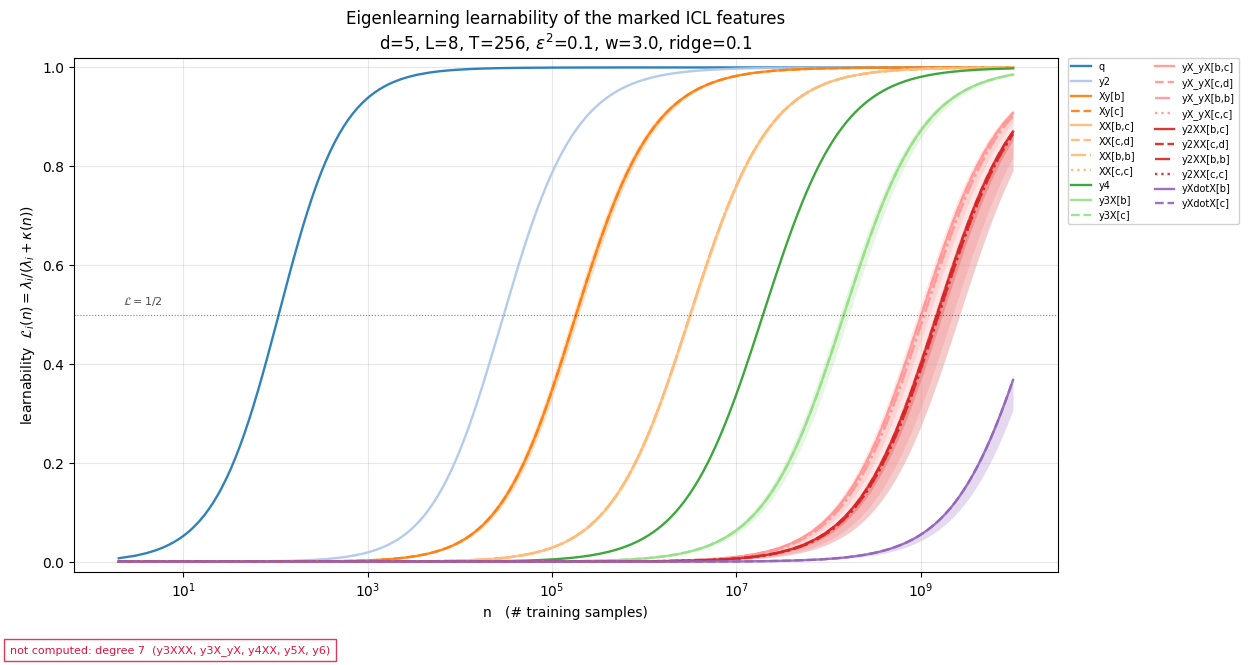

In [ ]:
# --- Figure 1: learnability vs n ----------------------------------------------------------
KIND_ORDER = ['q', 'y2', 'Xy', 'XX',
              'y4', 'y3X', 'y2XX', 'yX_yX', 'yXdotX',
              'y6', 'y5X', 'y4XX', 'y3XXX', 'y3X_yX']
KIND_COLOR = {k: plt.cm.tab20(i / 20.0) for i, k in enumerate(KIND_ORDER)}
# each kind has one colour (its degree is implied by the kind); classes *within* a kind are
# separated by line style, so e.g. XX[b,b] / XX[b,c] / XX[c,c] stay tellable apart.
_LS = ['-', '--', '-.', ':', (0, (5, 1)), (0, (3, 1, 1, 1)), (0, (1, 1))]

fig, ax = plt.subplots(figsize=(12.5, 6.4))
_seen_in_kind = {}
missing_kinds = []
for r in CLASS_ROWS:
    if not np.isfinite(r['lam']):
        missing_kinds.append(r['kind'])
        continue
    j = _seen_in_kind.get(r['kind'], 0)
    _seen_in_kind[r['kind']] = j + 1
    col = KIND_COLOR.get(r['kind'], 'grey')
    ax.plot(N_GRID, r['curve'], lw=1.7, color=col, ls=_LS[j % len(_LS)],
            alpha=0.92, label=r['name'])
    # where the finite-T betas break the isotropic degeneracy, shade the class's own spread
    if np.isfinite(r['lam_lo']) and r['lam_lo'] > 0 and r['lam_hi'] / r['lam_lo'] > 1.01:
        ax.fill_between(N_GRID, r['lam_lo'] / (r['lam_lo'] + KAPPA),
                        r['lam_hi'] / (r['lam_hi'] + KAPPA),
                        color=col, alpha=0.13, lw=0)

ax.axhline(0.5, color='k', lw=0.8, ls=':', alpha=0.5)
ax.text(N_GRID[0] * 1.1, 0.52, r'$\mathcal{L}=1/2$', fontsize=8, alpha=0.7)
ax.set_xscale('log')
ax.set_xlabel('n   (# training samples)')
ax.set_ylabel(r'learnability  $\mathcal{L}_i(n)=\lambda_i/(\lambda_i+\kappa(n))$')
ax.set_ylim(-0.02, 1.02)
ax.grid(alpha=0.3)
ax.set_title(f"Eigenlearning learnability of the marked ICL features\n"
             f"d={CFG['dim']}, L={CFG['L']}, T={CFG['T']}, "
             f"$\\epsilon^2$={CFG['sigma_sq']}, w={CFG['kernel_width']}, ridge={CFG['ridge']}")
ax.legend(fontsize=7, ncol=1 + len(CLASS_ROWS) // 26, loc='upper left',
          bbox_to_anchor=(1.01, 1.0), framealpha=0.9, borderaxespad=0.0)
_why = []
if NOT_COMPUTED_DEGREES:
    _why.append("not computed: degree " + ", ".join(str(d) for d in NOT_COMPUTED_DEGREES))
if UNAVAILABLE_DEGREES:
    _why.append("unavailable here: degree "
                + ", ".join(str(d) for d in sorted(UNAVAILABLE_DEGREES)))
if missing_kinds:
    fig.text(0.005, -0.015,
             "; ".join(_why) + f"  ({', '.join(sorted(set(missing_kinds)))})",
             ha='left', va='top', fontsize=8, color='crimson',
             bbox=dict(fc='white', ec='crimson', alpha=0.85))
plt.tight_layout()
plt.show()

In [ ]:
folder_path = '/content/drive/My Drive/picl/results/kernels/eigenstructure/'
file_path = os.path.join(folder_path, 'learnabilities_T256_L8_d5.pkl')
savedict = {
    "config": CFG,
    "results": {
        "N_GRID": N_GRID,
        "rows": CLASS_ROWS,
    }
}
os.makedirs(folder_path, exist_ok=True)
with open(file_path, 'wb') as f:
    pickle.dump(savedict, f)

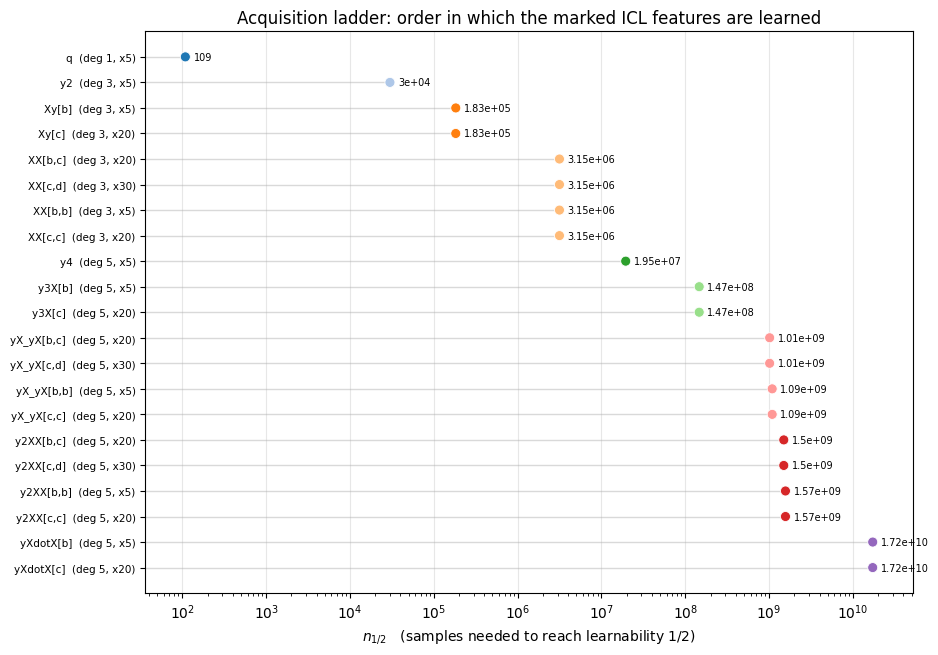

In [ ]:
# --- Figure 2: the acquisition ladder (n at which each term reaches L = 1/2) --------------
_rows = [r for r in CLASS_ROWS if np.isfinite(r['n_half'])]
_rows = sorted(_rows, key=lambda r: r['n_half'])

fig, ax = plt.subplots(figsize=(9.5, max(3.0, 0.26 * len(_rows) + 1.2)))
ypos = np.arange(len(_rows))
_x = np.array([r['n_half'] for r in _rows])
_lo = min(_x) / 3.0
# a dot plot, not bars: on a log axis a bar's LENGTH depends on where the axis floor happens
# to fall, so only the marker POSITION carries meaning.
ax.hlines(ypos, _lo, _x, color='0.85', lw=1.0, zorder=1)
ax.scatter(_x, ypos, s=52, zorder=3, edgecolor='white', linewidth=0.6,
           color=[KIND_COLOR.get(r['kind'], 'grey') for r in _rows])
for y, r in zip(ypos, _rows):
    ax.text(r['n_half'] * 1.25, y, f"{r['n_half']:.3g}", va='center', fontsize=7)
ax.set_xlim(_lo, max(_x) * 3.0)
ax.set_yticks(ypos)
ax.set_yticklabels([f"{r['name']}  (deg {r['degree']}, x{r['n_members']})" for r in _rows],
                   fontsize=7.5)
ax.set_xscale('log')
ax.set_xlabel(r'$n_{1/2}$   (samples needed to reach learnability $1/2$)')
ax.invert_yaxis()
ax.grid(alpha=0.3, axis='x')
ax.set_title("Acquisition ladder: order in which the marked ICL features are learned")
plt.tight_layout()
plt.show()

## 6. Save